# Figure 2 — Methylation: single-cell pseudobulk vs bulk WGBS over metilene DMRs

Compares **single-cell NOMe-HiC** endogenous CpG methylation (**HCG** context, GCG
removed) against **bulk WGBS** in **GM12878** and **IMR90**, over de-novo
differentially methylated regions.

**Pipeline**
1. DMRs called de novo on the bulk WGBS with **metilene** —
   `data_processing/bulk_others/03_differential/01_run_metilene_dmr.sh`
   → `analysis/dmr_metilene_hcg/metilene_GM12878_IMR90.dmr.txt`.
2. Single-cell pseudobulk pooled per cell type over those DMRs —
   `data_processing/mixture_cellline/03_pseudobulk/02_build_sc_pseudobulk_metilene_dmr.sh`
   → `sc_pseudobulk_metilene_dmr_top2000.tsv.gz`, which also carries the bulk means.
3. §3 keeps DMRs with ≥20 pooled reads in both cell types, **filters to those where the
   single-cell and bulk deltas agree in sign**, and plots the 200 most different per
   direction by |sc Δβ|.

The direction filter is **inert for this selection**, which is worth knowing: the 86
inconsistent DMRs have |sc Δβ| ≤ 0.257, while the weakest DMR that makes the top 200
is 0.681 (GM-hyper) / 0.724 (IMR-hyper). None of them could rank into the plotted set,
so the same 400 regions are chosen with or without the filter — verified directly
against `sc_pseudobulk_metilene_dmr_top2000.tsv.gz`. The direction scatter in the same
section shows all 3,890 covered DMRs regardless of consistency.

Run with the **R (`scnomehic_diff`)** kernel. Values are β (0–1).

**Published panels:** `metilene_dmr_pseudobulk_heatmap.pdf`, `metilene_dmr_colorbar.pdf`.


In [2]:
# --- repo paths: edit paths.yaml at the repository root, not this notebook ---
# Cached so that re-running this cell still works after it has setwd() away.
if (!exists(".repo_root")) {
  .r <- getwd()
  while (.r != "/" && !file.exists(file.path(.r, "paths.R"))) .r <- dirname(.r)
  stopifnot(file.exists(file.path(.r, "paths.R")))
  .repo_root <- .r
}
source(file.path(.repo_root, "paths.R"))

# §1 Setup
suppressPackageStartupMessages({
  library(ggplot2); library(patchwork); library(scales); library(data.table)
})
set.seed(42)

FIG2 <- file.path(WORK, "analysis/fig2")


## §2 Metilene de-novo DMRs — load and characterize

Loads the metilene de-novo DMR output (`analysis/dmr_metilene_hcg/metilene_GM12878_IMR90.dmr.txt`,
all DMRs that passed the calling floors `-m 10 -d 0.1`) and characterizes them: length, #CpGs,
methylation difference (meandiff = **GM12878 − IMR90**), group means, and significance.
Mirrors metilene_output.pl's basic plots, inline.

metilene DMRs: 213578 total | 32236 GM12878-hyper | 181342 IMR90-hyper
length: median 448 bp (IQR 248-691) | #CpGs: median 10 | q<0.05: 76126


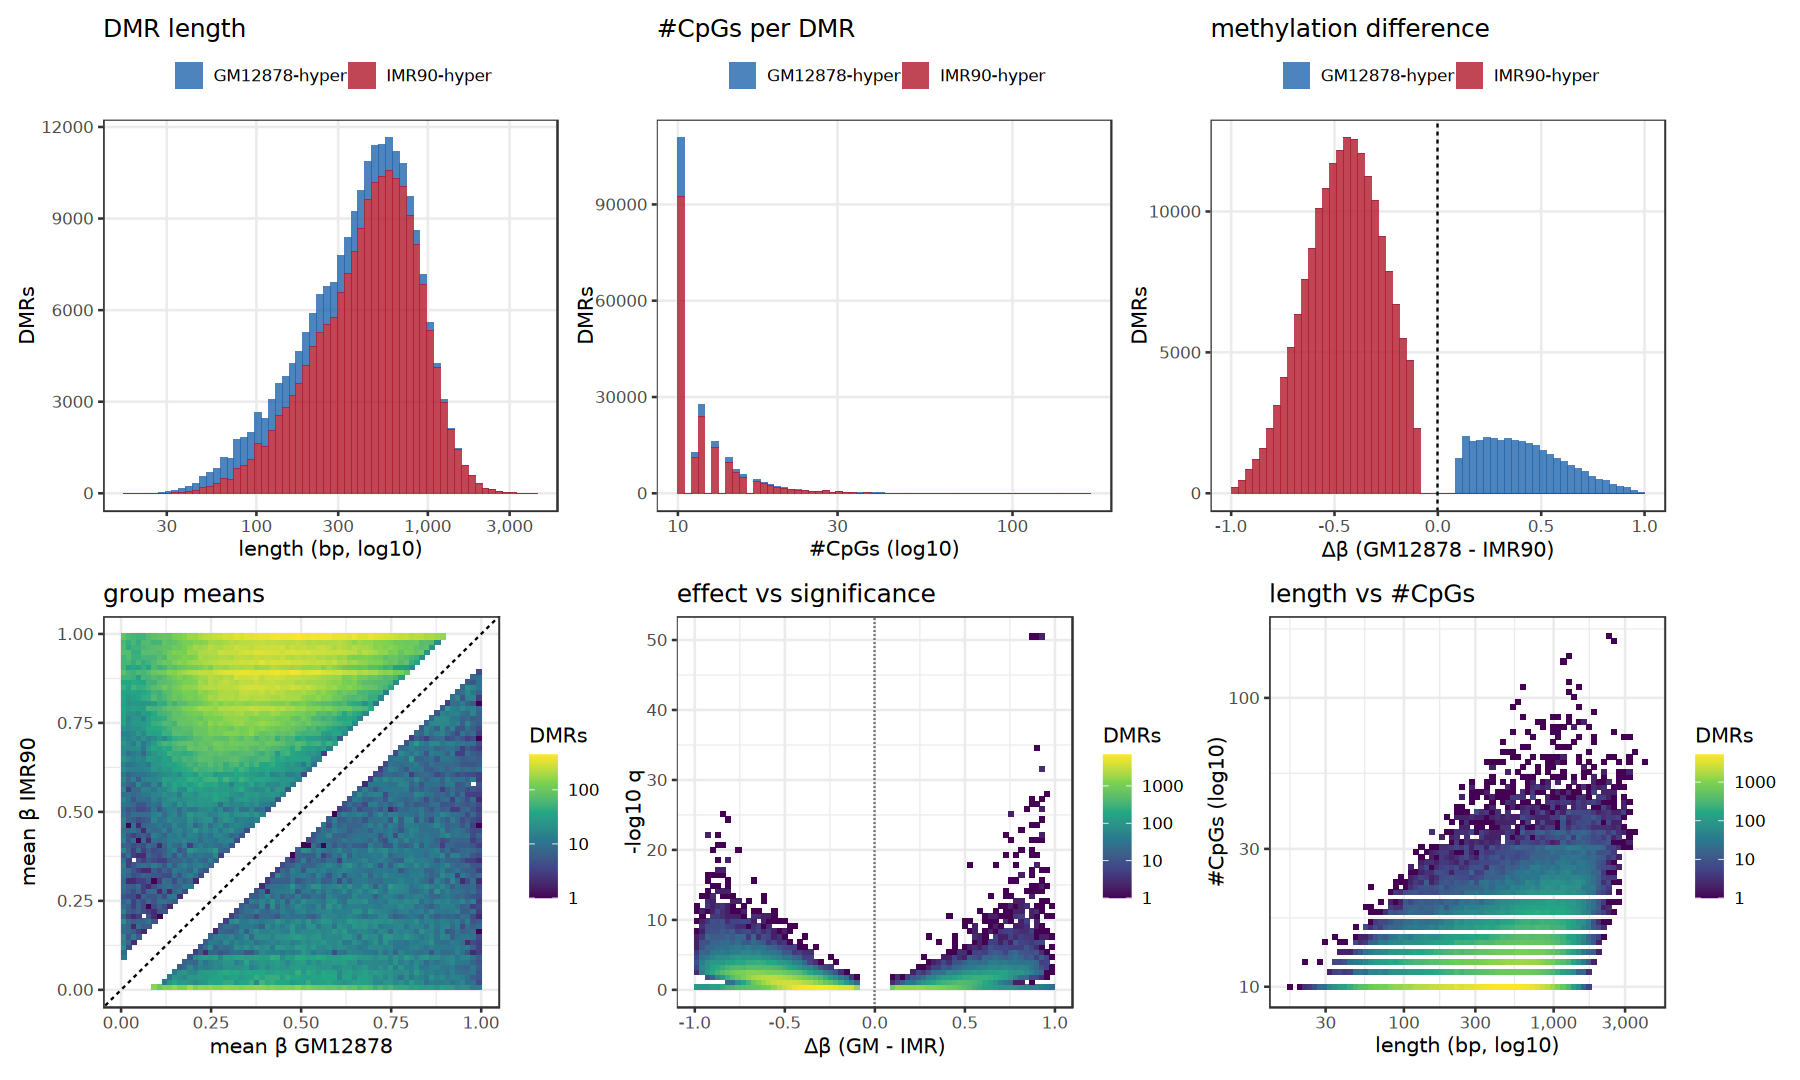

In [45]:
library(data.table); library(ggplot2); library(patchwork); library(scales)
MET_DMR <- file.path(FIG2, "analysis/dmr_metilene_hcg/metilene_GM12878_IMR90.dmr.txt")
met <- fread(MET_DMR, header = FALSE,
  col.names = c("chr","start","stop","qvalue","meandiff","nCpG","p_MWU","p_2DKS","mean_GM","mean_IMR"))
met[, length := stop - start]
met[, absdiff := abs(meandiff)]
met[, dir := ifelse(meandiff > 0, "GM12878-hyper", "IMR90-hyper")]   # meandiff = GM - IMR
cat(sprintf("metilene DMRs: %d total | %d GM12878-hyper | %d IMR90-hyper\n",
            nrow(met), sum(met$meandiff>0), sum(met$meandiff<0)))
cat(sprintf("length: median %d bp (IQR %d-%d) | #CpGs: median %d | q<0.05: %d\n",
            median(met$length), quantile(met$length,.25), quantile(met$length,.75),
            median(met$nCpG), sum(met$qvalue<0.05)))

dir_cols <- c("GM12878-hyper"="#2166AC", "IMR90-hyper"="#B2182B")
th <- theme_bw(base_size = 12) + theme(panel.grid.minor = element_blank(), legend.position = "top")

p_len <- ggplot(met, aes(length, fill = dir)) + geom_histogram(bins = 60, alpha = .8) +
  scale_x_log10(labels = comma) + scale_fill_manual(values = dir_cols, name = NULL) +
  labs(title = "DMR length", x = "length (bp, log10)", y = "DMRs") + th
p_cpg <- ggplot(met, aes(nCpG, fill = dir)) + geom_histogram(bins = 60, alpha = .8) +
  scale_x_log10() + scale_fill_manual(values = dir_cols, name = NULL) +
  labs(title = "#CpGs per DMR", x = "#CpGs (log10)", y = "DMRs") + th
p_diff <- ggplot(met, aes(meandiff, fill = dir)) + geom_histogram(bins = 60, alpha = .8) +
  geom_vline(xintercept = 0, linetype = 2) + scale_fill_manual(values = dir_cols, name = NULL) +
  labs(title = "methylation difference", x = expression(Delta*beta*" (GM12878 - IMR90)"), y = "DMRs") + th
p_mm <- ggplot(met, aes(mean_GM, mean_IMR)) + geom_bin2d(bins = 70) +
  scale_fill_viridis_c(trans = "log10", name = "DMRs") + geom_abline(linetype = 2) +
  labs(title = "group means", x = expression("mean "*beta*" GM12878"), y = expression("mean "*beta*" IMR90")) + theme_bw(base_size = 12)
p_vol <- ggplot(met, aes(meandiff, -log10(qvalue + 1e-300))) + geom_bin2d(bins = 70) +
  scale_fill_viridis_c(trans = "log10", name = "DMRs") + geom_vline(xintercept = 0, linetype = 3) +
  labs(title = "effect vs significance", x = expression(Delta*beta*" (GM - IMR)"), y = "-log10 q") +
  theme_bw(base_size = 12)
p_lc <- ggplot(met, aes(length, nCpG)) + geom_bin2d(bins = 70) +
  scale_fill_viridis_c(trans = "log10", name = "DMRs") + scale_x_log10(labels = comma) + scale_y_log10() +
  labs(title = "length vs #CpGs", x = "length (bp, log10)", y = "#CpGs (log10)") + theme_bw(base_size = 12)

charac <- (p_len | p_cpg | p_diff) / (p_mm | p_vol | p_lc)
ggsave(file.path(FIG2, "analysis/dmr_metilene_hcg/metilene_DMR_characterization.pdf"),
       charac, width = 15, height = 9)
options(repr.plot.width = 15, repr.plot.height = 9); charac


## §2b DMR counts under different filter criteria

How many DMRs survive combinations of significance (q-value) and effect-size (|Δβ|) cutoffs, split by
direction. (All DMRs already satisfy the calling floors #CpGs ≥ 10 and |Δβ| ≥ 0.1.) Use this to pick a
reference set for plotting.

  qval dabs total GM_hyper IMR_hyper
 0.001  0.1 14057     2030     12027
 0.001  0.2 14057     2030     12027
 0.001  0.3 14036     2026     12010
 0.001  0.5 12856     1877     10979
 0.010  0.1 41311     4878     36433
 0.010  0.2 41300     4878     36422
 0.010  0.3 41012     4843     36169
 0.010  0.5 34935     4203     30732
 0.050  0.1 76126     8483     67643
 0.050  0.2 75979     8467     67512
 0.050  0.3 74521     8317     66204
 0.050  0.5 56337     6402     49935


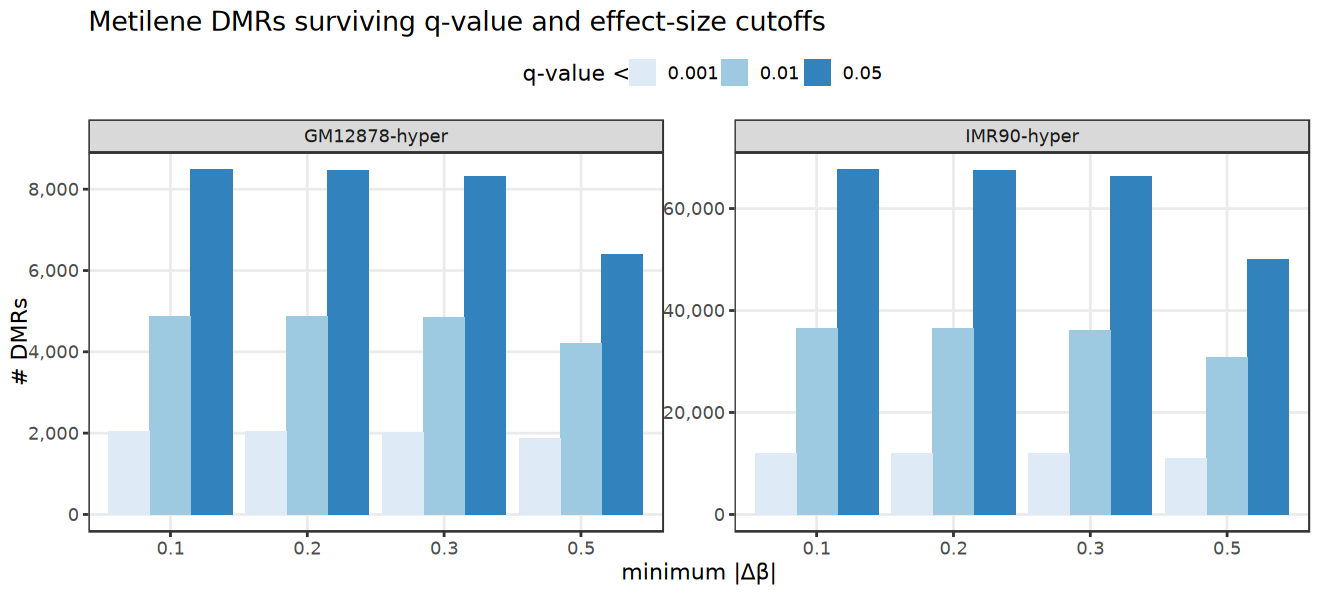

In [ ]:
qs <- c(0.05, 0.01, 0.001); ds <- c(0.1, 0.2, 0.3, 0.5)
grid <- expand.grid(qval = qs, dabs = ds)
res <- do.call(rbind, lapply(seq_len(nrow(grid)), function(i) {
  s <- met[qvalue < grid$qval[i] & absdiff >= grid$dabs[i]]
  data.frame(qval = grid$qval[i], dabs = grid$dabs[i],
             total = nrow(s), GM_hyper = sum(s$meandiff > 0), IMR_hyper = sum(s$meandiff < 0))
}))
print(res[order(res$qval, res$dabs), ], row.names = FALSE)

long <- rbind(
  data.frame(res, grp = "IMR90-hyper", n = res$IMR_hyper),
  data.frame(res, grp = "GM12878-hyper", n = res$GM_hyper))
p_crit <- ggplot(long, aes(factor(dabs), n, fill = factor(qval))) +
  geom_col(position = "dodge") +
  facet_wrap(~ grp, scales = "free_y") +
  scale_fill_brewer(palette = "Blues", name = "q-value <", direction = 1) +
  scale_y_continuous(labels = comma) +
  labs(title = "Metilene DMRs surviving q-value and effect-size cutoffs",
       x = expression("minimum |"*Delta*beta*"|"), y = "# DMRs") +
  theme_bw(base_size = 13) + theme(panel.grid.minor = element_blank(), legend.position = "top")
ggsave(file.path(FIG2, "analysis/dmr_metilene_hcg/metilene_DMR_criteria_counts.pdf"),
       p_crit, width = 11, height = 5)
options(repr.plot.width = 11, repr.plot.height = 5); p_crit


## §3 Single-cell pseudobulk over DMRs — direction check and heatmap

Loads `sc_pseudobulk_metilene_dmr_top2000.tsv.gz` (2000 IMR90-hyper + 2000 GM12878-hyper DMRs,
read-weighted sc pseudobulk per cell type + read counts). Steps: (1) coverage filter; (2) **check
direction** — does sc pseudobulk Δβ (IMR90−GM12878) agree in sign with the bulk DMR direction?
(scatter + %consistent); (3) among direction-consistent DMRs, **pick the most different ones**
(largest |sc Δβ|) per direction and plot pooled vs bulk WGBS (blue=low, yellow=high).

DMRs (cov>=20 both): 3890 | direction-consistent: 3804 (97.8%) | r(sc Δ, bulk Δ)=0.941
plotting 400 DMRs (200 IMR-hyper + 200 GM-hyper), most different by |sc Δβ|


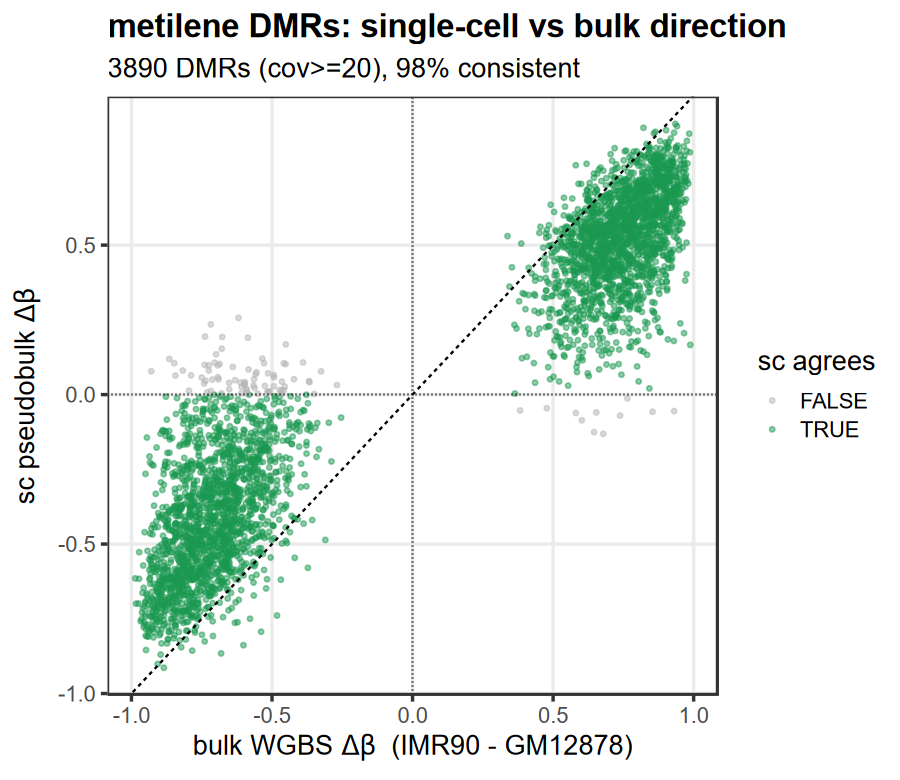

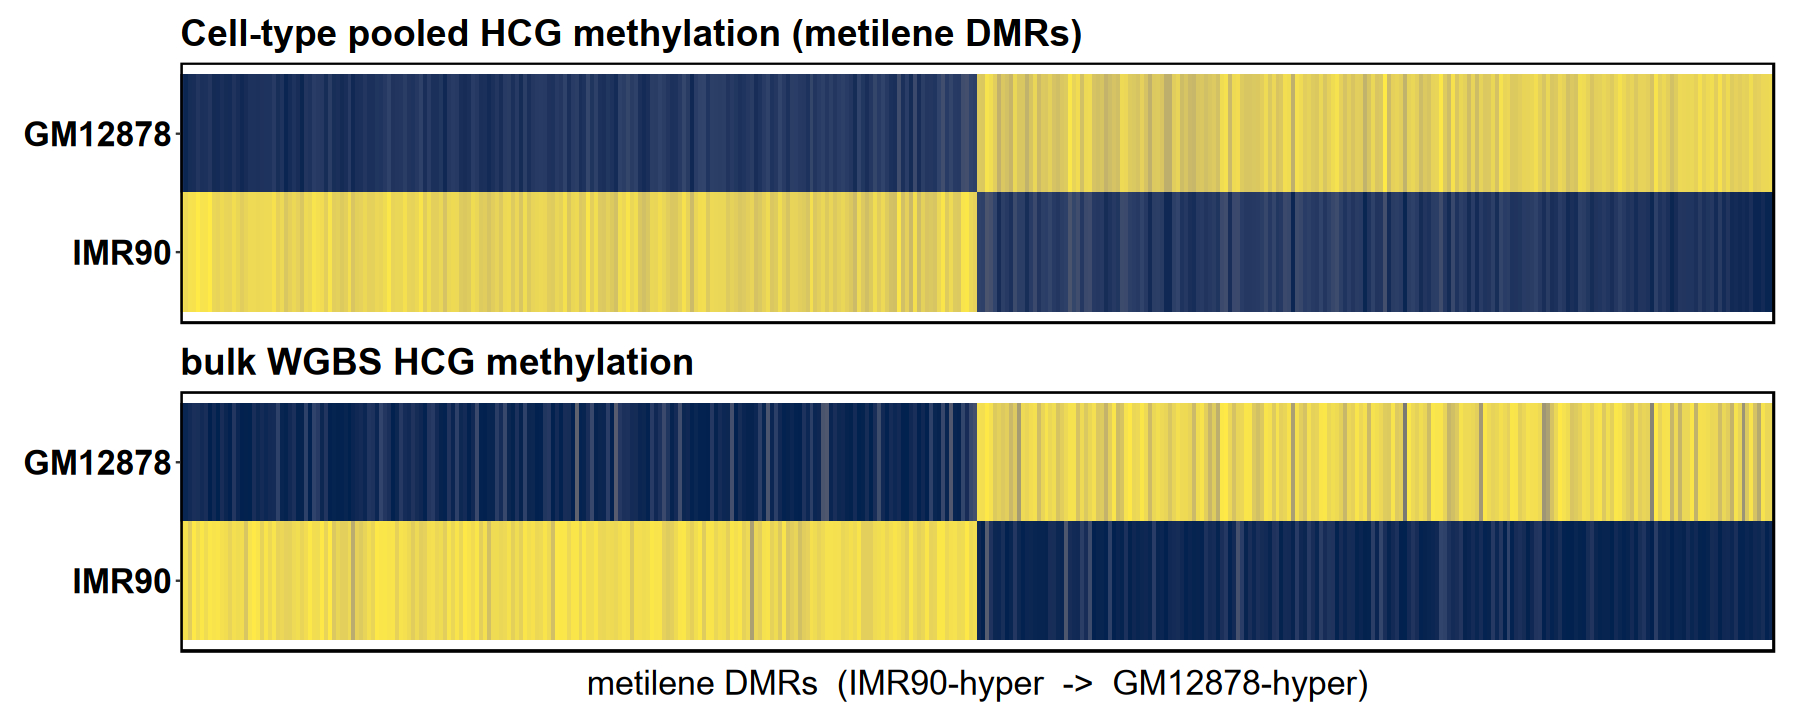

In [7]:
library(data.table); library(ggplot2); library(patchwork); library(scales)
mp <- as.data.frame(fread(file.path(FIG2,
        "analysis/dmr_metilene_hcg/sc_pseudobulk_metilene_dmr_top2000.tsv.gz")))

# ---- tunables ----
MIN_READS <- 20    # min pooled reads per cell type per DMR (coverage filter)
N_SHOW    <- 200   # DMRs per direction to plot (the most different by |sc Δβ|)

# coverage filter + deltas
mp <- mp[mp$GM12878_total >= MIN_READS & mp$IMR90_total >= MIN_READS, ]
mp$bulk_delta <- mp$bulk_mean_IMR - mp$bulk_mean_GM          # bulk WGBS IMR90 - GM12878
mp$sc_delta   <- mp$sc_delta_IMR_minus_GM                    # sc pseudobulk IMR90 - GM12878
mp$consistent <- sign(mp$sc_delta) == sign(mp$bulk_delta)
cat(sprintf("DMRs (cov>=%d both): %d | direction-consistent: %d (%.1f%%) | r(sc Δ, bulk Δ)=%.3f\n",
    MIN_READS, nrow(mp), sum(mp$consistent), 100*mean(mp$consistent),
    cor(mp$sc_delta, mp$bulk_delta, use="complete.obs")))

# ---- (1) direction check scatter ----
p_dir <- ggplot(mp, aes(bulk_delta, sc_delta, colour = consistent)) +
  geom_point(alpha = .5, size = .9) + geom_abline(linetype = 2) +
  geom_hline(yintercept = 0, linetype = 3) + geom_vline(xintercept = 0, linetype = 3) +
  scale_colour_manual(values = c("FALSE"="grey70","TRUE"="#1A9850"), name = "sc agrees") +
  labs(title = "metilene DMRs: single-cell vs bulk direction",
       subtitle = sprintf("%d DMRs (cov>=%d), %.0f%% consistent", nrow(mp), MIN_READS, 100*mean(mp$consistent)),
       x = expression("bulk WGBS "*Delta*beta*"  (IMR90 - GM12878)"),
       y = expression("sc pseudobulk "*Delta*beta)) +
  theme_bw(base_size = 16) + theme(plot.title=element_text(face="bold"), panel.grid.minor=element_blank())
ggsave(file.path(FIG2,"analysis/dmr_metilene_hcg/metilene_dmr_direction_scatter.pdf"), p_dir, width=7.5, height=6.5)
options(repr.plot.width=7.5, repr.plot.height=6.5); print(p_dir)

# ---- (2) pick most-different consistent DMRs (largest |sc Δβ|), per direction ----
cons <- mp[mp$consistent, ]; cons$absd <- abs(cons$sc_delta)
pick <- function(dr) { s <- cons[cons$dir==dr, ]; s[order(-s$absd), ][seq_len(min(N_SHOW, nrow(s))), ] }
selm <- rbind(pick("IMR90-hyper"), pick("GM12878-hyper"))
selm <- selm[order(-selm$sc_delta), ]                       # IMR90-hyper (Δ>0) left -> GM12878-hyper right
ids  <- selm$region_id
cat(sprintf("plotting %d DMRs (%d IMR-hyper + %d GM-hyper), most different by |sc Δβ|\n",
    length(ids), sum(selm$dir=="IMR90-hyper"), sum(selm$dir=="GM12878-hyper")))

# ---- (3) heatmap: pooled (top) + bulk WGBS (bottom), blue=low / yellow=high ----
meth_scale <- scale_fill_viridis_c(option="cividis", limits=c(0,1), na.value="grey90", oob=scales::squish)
pub_tile <- theme(axis.text.x=element_blank(), axis.ticks.x=element_blank(),
  axis.text.y=element_text(size=20, face="bold", colour="black"),
  axis.title.x=element_text(size=20, margin=margin(t=8)),
  panel.grid=element_blank(), panel.background=element_blank(),
  panel.border=element_rect(colour="black", fill=NA, linewidth=1.0),
  plot.title=element_text(size=22, face="bold"), legend.position="none", plot.margin=margin(6,10,6,10))
mk2 <- function(gmv, imrv, ttl) ggplot(
  data.frame(ref=factor(rep(c("GM12878","IMR90"), each=length(ids)), levels=c("IMR90","GM12878")),
             reg=factor(rep(ids, 2), levels=ids), beta=c(gmv, imrv)),
  aes(reg, ref, fill=beta)) + geom_tile() + meth_scale + labs(title=ttl, x=NULL, y=NULL) + pub_tile
p_pool <- mk2(selm$GM12878_beta, selm$IMR90_beta, "Cell-type pooled HCG methylation (metilene DMRs)")
p_bulk <- mk2(selm$bulk_mean_GM, selm$bulk_mean_IMR, "bulk WGBS HCG methylation") +
  labs(x="metilene DMRs  (IMR90-hyper  ->  GM12878-hyper)")
comb_m <- (p_pool / p_bulk) + plot_layout(heights=c(1,1))
ggsave(file.path(FIG2,"analysis/dmr_metilene_hcg/metilene_dmr_pseudobulk_heatmap.pdf"), comb_m, width=15, height=6)
options(repr.plot.width=15, repr.plot.height=6); comb_m


### §3b Colorbar

The heatmaps are drawn with `legend.position = "none"`, so the colour scale is rendered here as a
standalone **horizontal colorbar**, in the same format/size as the accessibility notebook's 7d
`cbar()` (title above, 16pt ticks, 6.6 x 1.2 in per bar). Methylation needs only **one** bar — the
pooled and bulk WGBS panels share the identical HCG β scale (cividis: blue = low, yellow = high, 0–1).

wrote -> metilene_dmr_colorbar.pdf (6.6 x 1.2 in, one bar)


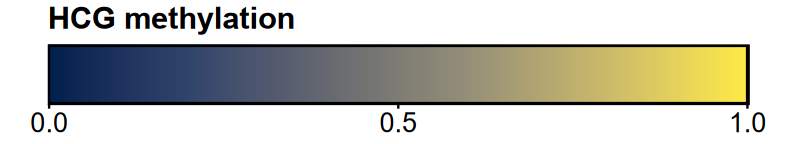

In [ ]:
# Colorbar in the same format/size as the accessibility notebook's 7d cbar():
# one bar only (pooled + bulk panels share the same HCG beta scale). 6.6 x 1.2 in = one 7d bar.
OUTM <- file.path(FIG2, "analysis/dmr_metilene_hcg")

cbar_meth <- function(lo = 0, hi = 1, title = "HCG methylation", fmt = "%.1f", n = 256) {
  d <- data.frame(x = seq(lo, hi, length.out = n), y = 1)
  ggplot(d, aes(x, y, fill = x)) + geom_raster() +
    scale_fill_viridis_c(option = "cividis", limits = c(lo, hi), guide = "none",
                         oob = scales::squish) +
    scale_x_continuous(breaks = c(lo, (lo+hi)/2, hi),
                       labels = function(b) sprintf(fmt, b), expand = c(0,0)) +
    scale_y_continuous(expand = c(0,0)) +
    labs(title = title, x = NULL, y = NULL) +
    theme(axis.text.x = element_text(size = 16, colour = "black"),
          axis.ticks.x = element_line(colour = "black"),
          axis.text.y = element_blank(), axis.ticks.y = element_blank(),
          panel.background = element_blank(), panel.grid = element_blank(),
          panel.border = element_rect(colour = "black", fill = NA, linewidth = 1.1),
          plot.title = element_text(size = 18, face = "bold"),
          plot.margin = margin(4, 26, 4, 26))
}

cb_meth <- cbar_meth(0, 1, "HCG methylation")
ggsave(file.path(OUTM, "metilene_dmr_colorbar.pdf"), cb_meth, width = 6.6, height = 1.2)
cat("wrote -> metilene_dmr_colorbar.pdf (6.6 x 1.2 in, one bar)\n")
options(repr.plot.width = 6.6, repr.plot.height = 1.2); cb_meth
